In [ ]:
#########################################################
### Author: Spenser
### Date: 1 Feb 2026
### Description: Test case of the pipeline using a Crandall Cemetery

#########################################################

In [1]:
### Import Modules
#Path
from pathlib import Path
import sys
import os 

##  Attributes 
proj_fname = Path(os.path.abspath('')).parents[3].joinpath('grass-projects/unmarkedgraves-test/crandall').resolve()
historic_fname = Path(os.path.abspath('')).joinpath(r'Nassau_Sites.shp').resolve()
lidar_fname = Path(os.path.abspath('')).joinpath(r'USGS_LPC_FL_Peninsular_FDEM_2018_D19_DRRA_LID2019_210659_E.laz').resolve()

# Import the Model
try:
    from unmarked_graves_pipeline import UnmarkedGraves
except ImportError:
    sys.path.append("..")
    from unmarked_graves_pipeline import UnmarkedGraves

In [2]:
### Running as Grass Jupyter 
ug = UnmarkedGraves()

## Setup Env
ug.setup_grass_env(lidar_file= lidar_fname
                   ,project_path=proj_fname)

## Ensuring Grass Jupyter is initialized
ug.gj.init(proj_fname)

Historical Site Buffer is complete. Find it in Grass GIS under file name 
 Nassau_Sites_*_buffered 


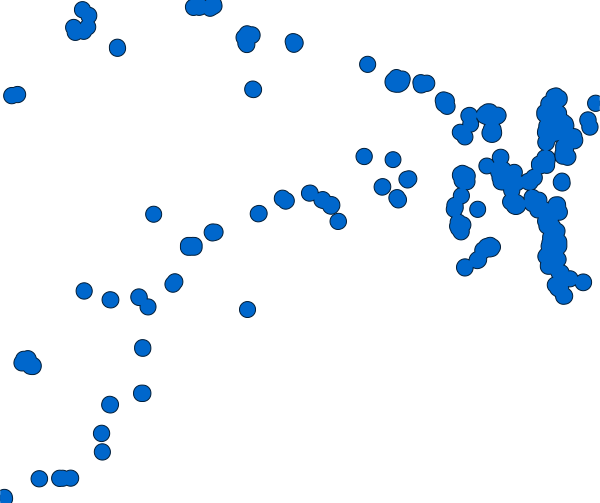

In [3]:
### Historical Buffer
## Creating the buffer
ug.historical_sites_check(historical_file = historic_fname)

## Display the 1/4 and 1/2 mi buffers
crandall_hist_map = ug.gj.Map()

# 1/4 mi buffer
crandall_hist_map.d_vect(map=f'{historic_fname.stem}_quart_mi_buffered')

# 1/2 mi buffer
crandall_hist_map.d_vect(map=f'{historic_fname.stem}_half_mi_buffered')

# Display
crandall_hist_map.show()

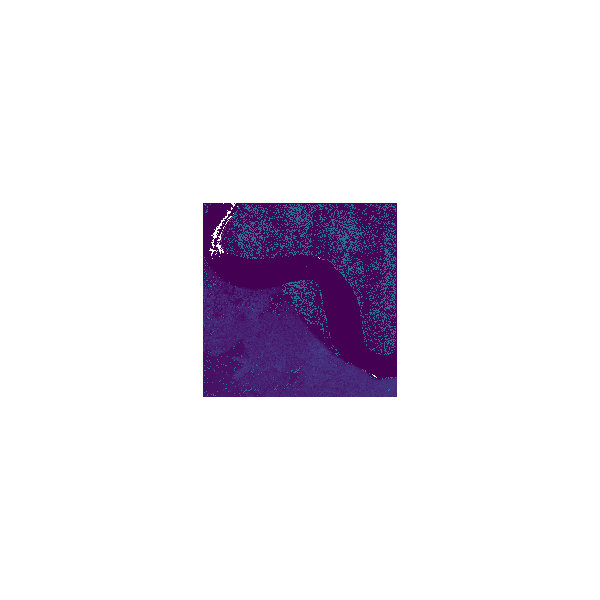

In [ ]:
### Elevation 
## Running Elevation Check
ug.elevation_check(low_memory=True)

## Display LiDAR File and Points of Interest
crandall_elev_map = ug.gj.Map()
# LiDAR File
crandall_elev_map.d_rast(map= f'{lidar_fname.stem[-15:]}_mean_neighbor')

# Points of Interest
crandall_elev_map.d_rast(map='diff_fin_wide')

# Display
crandall_elev_map.show()


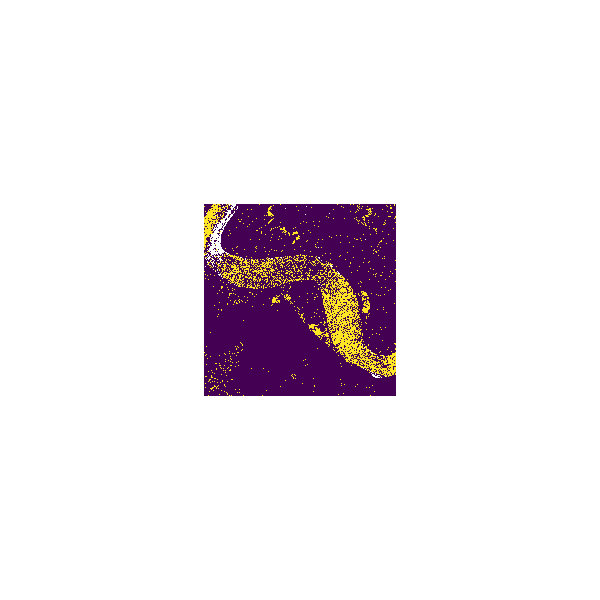

In [5]:
### Topology 
ug.topology_check(low_memory= True)

## Display Topology Layer
crandall_topo_map = ug.gj.Map()

# Pit Basin
crandall_topo_map.d_rast(map='pit_basin_filter_wide')

# Display
crandall_topo_map.show()

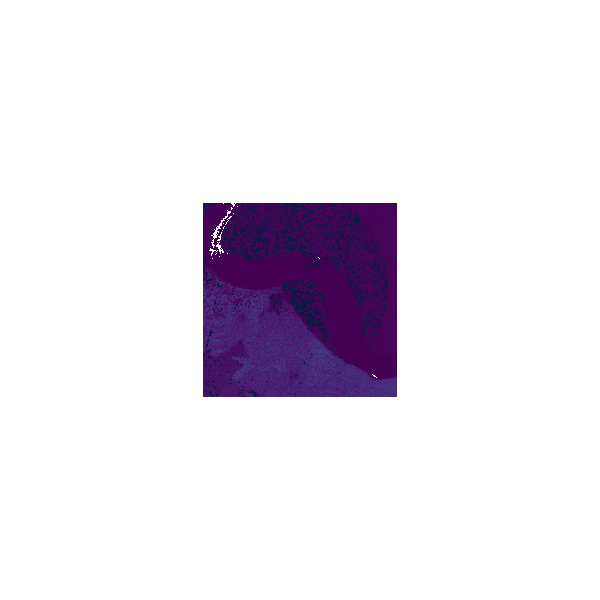

In [6]:
### Final Red and Amber Sites
ug.rag_ranking(low_memory= True, shapefile=True)

## Display Red and Amber Sites
crandall_ranked_map = ug.gj.Map()

# Add Lidar Background
crandall_ranked_map.d_rast(map=f'{lidar_fname.stem[-15:]}_mean_neighbor')
# Red Sites
crandall_ranked_map.d_vect(map='red_sites_grow_vect')

# Amber Sites
crandall_ranked_map.d_vect(map='amber_sites_grow_vect')

# Display
crandall_ranked_map.show()